# Lab 7: Reinforcement Learning (RL) Basics (Tabular)

This notebook is designed for **Google Colab (12 GB RAM)** and focuses on **tabular** RL (no deep networks).

Learning objectives:
- Formalise interaction as an **agent–environment** loop
- Implement and evaluate **ε-greedy** exploration
- Solve a simple environment with **Q-learning**
- Inspect learning curves and discuss common failure modes

**Expected time:** 60–90 minutes.


## 0. Setup
We use only standard scientific Python libraries (`numpy`, `matplotlib`).

> Optional: If you want to try Gymnasium environments, a cell is provided later. The main notebook does **not** depend on it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Tuple, Dict, List, Optional

np.random.seed(42)

def moving_average(x, window=50):
    if len(x) < window:
        return np.array(x, dtype=float)
    x = np.array(x, dtype=float)
    return np.convolve(x, np.ones(window)/window, mode="valid")

print("Libraries imported.")

Libraries imported.


## 1. Warm-up: Multi-Armed Bandits (No State)
A **k-armed bandit** is the simplest RL-like setting:
- There is **no state** (or state is constant).
- The agent chooses an action (arm) and receives a reward.
- The goal is to **maximise expected reward**.

This setting is ideal for understanding **exploration vs exploitation**.

In [2]:
class BernoulliBandit:
    """k-armed Bernoulli bandit with fixed reward probabilities."""
    def __init__(self, p: np.ndarray):
        assert p.ndim == 1
        self.p = p.astype(float)
        self.k = len(p)

    def step(self, action: int) -> float:
        # Reward is 1 with probability p[action], else 0
        return 1.0 if np.random.rand() < self.p[action] else 0.0


def epsilon_greedy_bandit(bandit: BernoulliBandit, steps: int, epsilon: float = 0.1):
    """ε-greedy for a bandit using sample-average value estimates."""
    k = bandit.k
    Q = np.zeros(k)         # estimated value of each arm
    N = np.zeros(k)         # count of pulls for each arm
    rewards = []

    for t in range(steps):
        explore = np.random.rand() < epsilon
        if explore:
            a = np.random.randint(k)
        else:
            a = int(np.argmax(Q))

        r = bandit.step(a)
        rewards.append(r)

        # Incremental sample-average update:
        N[a] += 1
        Q[a] += (r - Q[a]) / N[a]

    return np.array(rewards), Q, N


# Example bandit: one arm is best, but not obvious
p = np.array([0.10, 0.20, 0.05, 0.40, 0.35])
bandit = BernoulliBandit(p)

rewards, Q, N = epsilon_greedy_bandit(bandit, steps=2000, epsilon=0.1)

print("True probabilities:", p)
print("Estimated values Q:", np.round(Q, 3))
print("Pull counts N:", N.astype(int))

True probabilities: [0.1  0.2  0.05 0.4  0.35]
Estimated values Q: [0.097 0.195 0.097 0.394 0.321]
Pull counts N: [  72   41   31 1803   53]


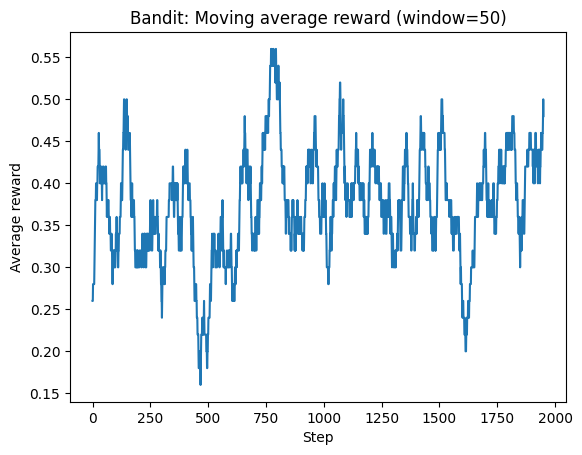

In [3]:
plt.figure()
plt.plot(moving_average(rewards, window=50))
plt.title("Bandit: Moving average reward (window=50)")
plt.xlabel("Step")
plt.ylabel("Average reward")
plt.show()

### Exercise 1 (Bandits)
1. Change `epsilon` to `0.0`, `0.01`, `0.5`. What happens?
2. Increase `steps` to `20000`. Do the estimates converge?
3. Replace sample-average updates with a **constant step size** (e.g., `alpha=0.1`). When is that useful?

Write your observations below.

## 2. Markov Decision Process (MDP) Mini-Environment: GridWorld
Now we introduce **state** and **episodes**.

We define a small deterministic GridWorld:
- State: agent position `(row, col)`
- Actions: up, down, left, right
- Reward: `-1` per step, `+10` upon reaching the goal
- Episode ends when the goal is reached or the step limit is exceeded

This environment is intentionally simple so that we can implement tabular RL from first principles.

In [4]:
Action = int  # 0:up, 1:down, 2:left, 3:right

@dataclass
class StepResult:
    next_state: int
    reward: float
    done: bool

class GridWorld:
    def __init__(self, height=5, width=5, start=(0,0), goal=(4,4), max_steps=200):
        self.h = height
        self.w = width
        self.start = start
        self.goal = goal
        self.max_steps = max_steps
        self.reset()

    def _state_to_id(self, r: int, c: int) -> int:
        return r * self.w + c

    def _id_to_state(self, s: int) -> Tuple[int, int]:
        return divmod(s, self.w)

    @property
    def n_states(self) -> int:
        return self.h * self.w

    @property
    def n_actions(self) -> int:
        return 4

    def reset(self) -> int:
        self.r, self.c = self.start
        self.t = 0
        return self._state_to_id(self.r, self.c)

    def step(self, action: Action) -> StepResult:
        self.t += 1

        # Proposed move
        nr, nc = self.r, self.c
        if action == 0:   # up
            nr -= 1
        elif action == 1: # down
            nr += 1
        elif action == 2: # left
            nc -= 1
        elif action == 3: # right
            nc += 1
        else:
            raise ValueError("Invalid action")

        # Boundary conditions: if hit wall, stay in place
        nr = np.clip(nr, 0, self.h - 1)
        nc = np.clip(nc, 0, self.w - 1)

        self.r, self.c = int(nr), int(nc)

        done = (self.r, self.c) == self.goal or self.t >= self.max_steps
        reward = 10.0 if (self.r, self.c) == self.goal else -1.0

        return StepResult(
            next_state=self._state_to_id(self.r, self.c),
            reward=reward,
            done=done
        )


env = GridWorld(height=5, width=5, start=(0,0), goal=(4,4), max_steps=100)
print("States:", env.n_states, "Actions:", env.n_actions)
s0 = env.reset()
print("Start state id:", s0)

States: 25 Actions: 4
Start state id: 0


### Visualisation helper
This is **not** required for learning, but it helps interpretation.

In [5]:
def render_gridworld(env: GridWorld, policy: Optional[np.ndarray] = None):
    """Simple text rendering; policy can be shape (n_states,) with best action per state."""
    grid = [["·" for _ in range(env.w)] for _ in range(env.h)]
    sr, sc = env.start
    gr, gc = env.goal
    grid[sr][sc] = "S"
    grid[gr][gc] = "G"
    grid[env.r][env.c] = "A"

    print("GridWorld (S=start, G=goal, A=agent):")
    for row in grid:
        print(" ".join(row))

render_gridworld(env)

GridWorld (S=start, G=goal, A=agent):
A · · · ·
· · · · ·
· · · · ·
· · · · ·
· · · · G


## 3. Tabular Q-learning
We maintain a table `Q[s, a]` and update it from experience:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,[r + \gamma\max_{a'} Q(s',a') - Q(s,a)]$$

Key hyperparameters:
- `alpha` (learning rate)
- `gamma` (discount factor)
- `epsilon` (exploration probability)

We also separate **training** from **evaluation** to avoid misleading results.

In [6]:
def epsilon_greedy_action(Q: np.ndarray, state: int, epsilon: float) -> int:
    if np.random.rand() < epsilon:
        return np.random.randint(Q.shape[1])
    return int(np.argmax(Q[state]))


def q_learning(
    env: GridWorld,
    episodes: int = 500,
    alpha: float = 0.1,
    gamma: float = 0.99,
    epsilon: float = 0.1,
    epsilon_decay: float = 0.995,
    min_epsilon: float = 0.01,
    eval_every: int = 50,
    eval_episodes: int = 20,
):
    Q = np.zeros((env.n_states, env.n_actions), dtype=float)
    train_returns = []
    eval_returns = []

    def run_episode_greedy(Q_eval: np.ndarray) -> float:
        s = env.reset()
        total = 0.0
        done = False
        while not done:
            a = int(np.argmax(Q_eval[s]))
            out = env.step(a)
            total += out.reward
            s = out.next_state
            done = out.done
        return total

    for ep in range(1, episodes + 1):
        s = env.reset()
        total = 0.0
        done = False

        while not done:
            a = epsilon_greedy_action(Q, s, epsilon)
            out = env.step(a)
            s_next, r, done = out.next_state, out.reward, out.done
            total += r

            # Q-learning update (off-policy, bootstraps using max over next actions)
            td_target = r + gamma * (0.0 if done else np.max(Q[s_next]))
            Q[s, a] += alpha * (td_target - Q[s, a])

            s = s_next

        train_returns.append(total)

        # Epsilon decay (common practical heuristic)
        epsilon = max(min_epsilon, epsilon * epsilon_decay)

        # Periodic evaluation with greedy policy (epsilon=0)
        if ep % eval_every == 0:
            scores = [run_episode_greedy(Q) for _ in range(eval_episodes)]
            eval_returns.append((ep, float(np.mean(scores))))

    return Q, np.array(train_returns), np.array(eval_returns, dtype=float)


env = GridWorld(height=5, width=5, start=(0,0), goal=(4,4), max_steps=100)

Q, train_returns, eval_returns = q_learning(
    env,
    episodes=800,
    alpha=0.2,
    gamma=0.95,
    epsilon=0.3,
    epsilon_decay=0.995,
    min_epsilon=0.02,
    eval_every=50,
    eval_episodes=30
)

print("Training complete.")
print("Last 5 training returns:", train_returns[-5:])

Training complete.
Last 5 training returns: [3. 3. 3. 3. 3.]


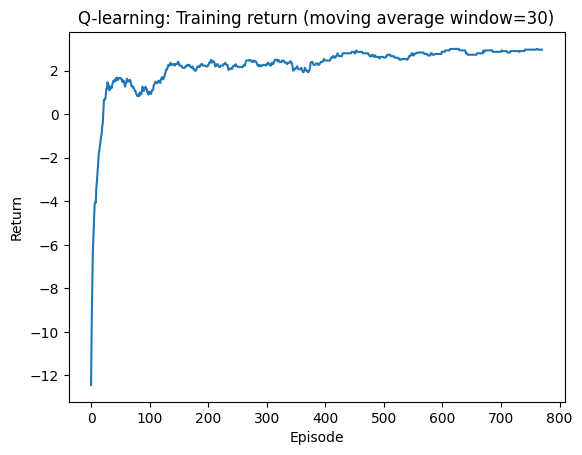

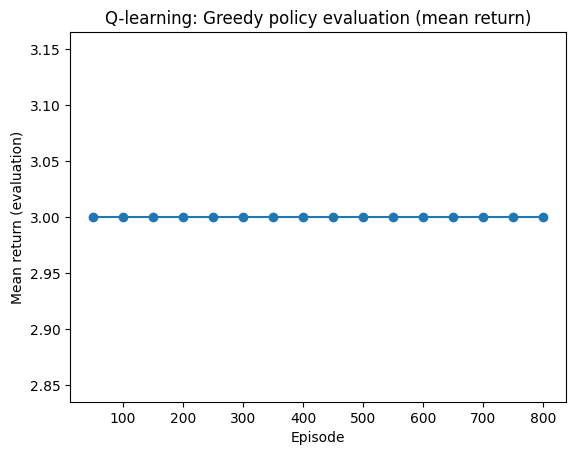

In [7]:
plt.figure()
plt.plot(moving_average(train_returns, window=30))
plt.title("Q-learning: Training return (moving average window=30)")
plt.xlabel("Episode")
plt.ylabel("Return")
plt.show()

plt.figure()
plt.plot(eval_returns[:,0], eval_returns[:,1], marker="o")
plt.title("Q-learning: Greedy policy evaluation (mean return)")
plt.xlabel("Episode")
plt.ylabel("Mean return (evaluation)")
plt.show()

### Extract and display the learned greedy policy
We show the **best action** at each state according to `argmax_a Q[s,a]`.

Legend: `↑, ↓, ←, →`.

In [8]:
arrow = {0:"↑", 1:"↓", 2:"←", 3:"→"}

def policy_from_Q(Q: np.ndarray) -> np.ndarray:
    return np.argmax(Q, axis=1)

def print_policy(env: GridWorld, policy: np.ndarray):
    for r in range(env.h):
        row = []
        for c in range(env.w):
            s = r * env.w + c
            if (r, c) == env.goal:
                row.append("G")
            elif (r, c) == env.start:
                row.append("S")
            else:
                row.append(arrow[int(policy[s])])
        print(" ".join(row))

pi = policy_from_Q(Q)
print_policy(env, pi)

S ↓ ↓ ↓ ↓
→ → → ↓ ↓
→ → → → ↓
← → → → ↓
↓ → → → G


### Exercise 2 (Q-learning)
1. Change `gamma` to `0.50` and `0.99`. How does behaviour change?
2. Set `alpha` too high (e.g., `0.9`) and too low (e.g., `0.01`). What happens?
3. Increase grid size to `8×8`. What must you adjust (episodes, epsilon decay, max_steps)?

Write your observations below.

## 4. Common evaluation pitfalls
A frequent mistake is to report training returns **while still exploring**.

Below, we compare:
- training returns (ε-greedy)
- greedy evaluation returns (ε=0)

When exploration is high, training return can look worse than the true learned performance.

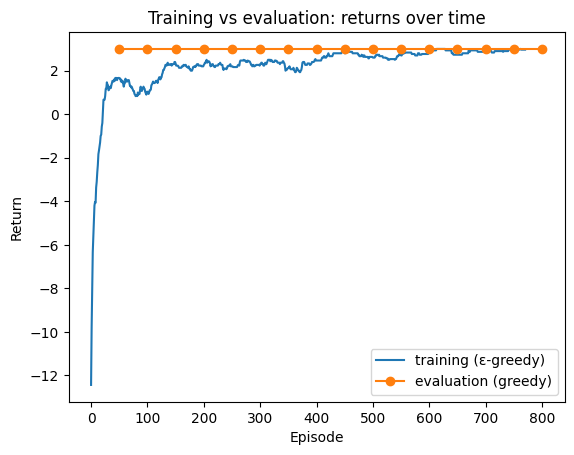

In [9]:
# Plot both series on comparable x-axes (episodes)
plt.figure()
plt.plot(moving_average(train_returns, window=30), label="training (ε-greedy)")
plt.plot(eval_returns[:,0], eval_returns[:,1], marker="o", label="evaluation (greedy)")
plt.title("Training vs evaluation: returns over time")
plt.xlabel("Episode")
plt.ylabel("Return")
plt.legend()
plt.show()

## 5. Optional extension: SARSA (On-policy)
SARSA updates using the **actual next action** chosen under the current behaviour policy:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,[r + \gamma Q(s',a') - Q(s,a)]$$

In some environments (especially with risky states), SARSA can learn safer behaviour than Q-learning.

Below is a minimal implementation. Compare learning curves with Q-learning.

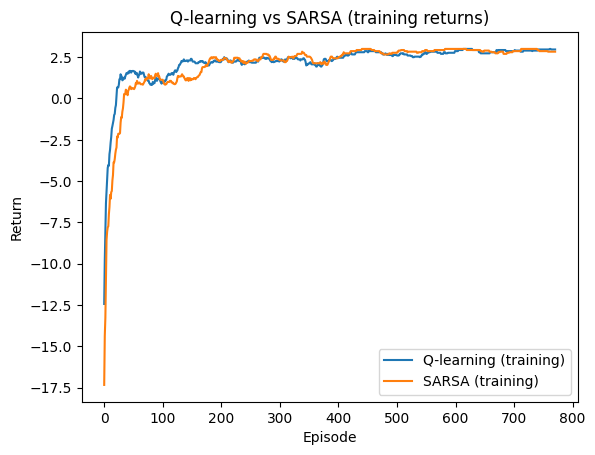

In [10]:
def sarsa(
    env: GridWorld,
    episodes: int = 500,
    alpha: float = 0.1,
    gamma: float = 0.99,
    epsilon: float = 0.1,
    epsilon_decay: float = 0.995,
    min_epsilon: float = 0.01,
):
    Q = np.zeros((env.n_states, env.n_actions), dtype=float)
    returns = []

    for ep in range(episodes):
        s = env.reset()
        a = epsilon_greedy_action(Q, s, epsilon)
        total = 0.0
        done = False

        while not done:
            out = env.step(a)
            s_next, r, done = out.next_state, out.reward, out.done
            total += r

            if done:
                td_target = r
                Q[s, a] += alpha * (td_target - Q[s, a])
                break

            a_next = epsilon_greedy_action(Q, s_next, epsilon)
            td_target = r + gamma * Q[s_next, a_next]
            Q[s, a] += alpha * (td_target - Q[s, a])

            s, a = s_next, a_next

        returns.append(total)
        epsilon = max(min_epsilon, epsilon * epsilon_decay)

    return Q, np.array(returns)


env = GridWorld(height=5, width=5, start=(0,0), goal=(4,4), max_steps=100)

Q_sarsa, returns_sarsa = sarsa(env, episodes=800, alpha=0.2, gamma=0.95, epsilon=0.3)

plt.figure()
plt.plot(moving_average(train_returns, 30), label="Q-learning (training)")
plt.plot(moving_average(returns_sarsa, 30), label="SARSA (training)")
plt.title("Q-learning vs SARSA (training returns)")
plt.xlabel("Episode")
plt.ylabel("Return")
plt.legend()
plt.show()

## 6. Optional: Gymnasium (if you want a standard benchmark)
This section is **optional**.

Gymnasium provides standard environments (e.g., `FrozenLake-v1`).
In Colab, installation can sometimes be slow depending on the runtime image.

**If you skip this part, the notebook is still complete.**

In [11]:
# OPTIONAL (uncomment if you want Gymnasium environments)
# !pip -q install gymnasium

print("If you installed gymnasium, you can import it and adapt the Q-learning loop.")

If you installed gymnasium, you can import it and adapt the Q-learning loop.


## 7. Exit Ticket (Short Assessment)
Answer in 3–6 sentences each:

1. In your own words, what is the difference between a **bandit** and an **MDP**?
2. Why do we separate **training** and **evaluation** in RL experiments?
3. What does the hyperparameter `γ` (discount factor) control?
4. Describe one failure mode of ε-greedy exploration.


## 8. Challenge tasks (Optional)
Choose one:
- **Reward shaping**: change the reward to encourage shorter paths, then observe if it introduces unintended behaviour.
- **Stochasticity**: add a probability that the action slips to a random action (like FrozenLake). Does Q-learning still converge?
- **Cliff**: add a 'cliff' region with large negative reward. Compare Q-learning and SARSA behaviour.

Document what you changed and report learning curves.